# Rețele neuronale și deep learning — Cursul 4: Rețele neuronale convoluționale (CNN) și transferul învățării
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București (ASE); Academia Română, Institutul de Prognoză Economică (IPE)

[Deschide în Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L4_notebook_ro.ipynb)

Acest notebook reproduce cifrele și graficele cursului pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe slide-uri.

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Fotografiile de produse ca date (Fashion-MNIST)

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
VISION = '../data/raw/vision'                 # torchvision downloads Fashion-MNIST and EuroSAT here on first use
os.makedirs(VISION, exist_ok=True)
fm_tr = torchvision.datasets.FashionMNIST(VISION, train=True, download=True)
fm_te = torchvision.datasets.FashionMNIST(VISION, train=False, download=True)
X = fm_tr.data.numpy().astype(np.float32) / 255; y = fm_tr.targets.numpy()
Xte = fm_te.data.numpy().astype(np.float32) / 255; yte = fm_te.targets.numpy()
perm = np.random.RandomState(SEED).permutation(len(X)); itr, iva = perm[:50000], perm[50000:]
MU, SD = X[itr].mean(), X[itr].std()            # scaling fitted on the training part only
T = lambda a: torch.tensor((a - MU) / SD).unsqueeze(1)
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(len(itr), len(iva), len(Xte), round(float(MU), 4), round(float(SD), 4))

50000 10000 10000 0.2859 0.353


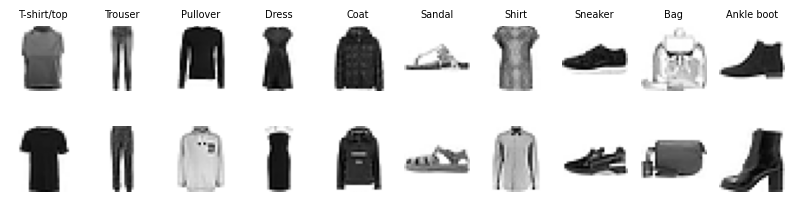

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for c in range(10):
    ids = np.where(y[itr] == c)[0][:2]
    for r in range(2):
        axes[r, c].imshow(X[itr][ids[r]], cmap='gray_r'); axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=7)
plt.show()

## §2 O convoluție calculată de mînă

Dimensiunea ieșirii $\lfloor (H+2p-k)/s \rfloor + 1$; nuclee Sobel pe o imagine reală.

64 62 32


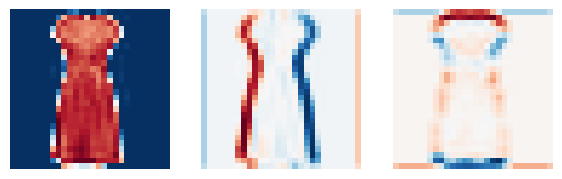

In [5]:
out_size = lambda H, k, p, s: (H + 2 * p - k) // s + 1
print(out_size(64, 3, 1, 1), out_size(64, 3, 0, 1), out_size(64, 3, 1, 2))
Kx = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]])
img = torch.tensor((X[itr][0] - MU) / SD)[None, None]
ex = F.conv2d(img, Kx[None, None], padding=1)[0, 0]; ey = F.conv2d(img, Kx.T[None, None], padding=1)[0, 0]
fig, ax = plt.subplots(1, 3, figsize=(7, 2.4))
for a, im in zip(ax, [img[0, 0], ex, ey]):
    a.imshow(im, cmap='RdBu_r'); a.axis('off')
plt.show()

## §3 Regresia softmax, MLP și CNN

Aici, o singură sămînță și 6 epoci (pe slide-uri: 3 semințe, 12 epoci).

In [6]:
def evaluate(m, Xt, yt, bs=1000):
    m.eval(); out = []
    with torch.no_grad():
        for j in range(0, len(Xt), bs):
            out.append(m(Xt[j:j + bs].to(DEVICE)).cpu())
    p = torch.cat(out).argmax(1).numpy()
    return float((p == yt).mean()), p

def fit(m, Xtr, ytr, Xva, yva, epochs=6, lr=1e-3, bs=128):
    torch.manual_seed(SEED); m = m.to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3 * lr, total_steps=epochs * int(np.ceil(len(Xtr) / bs)))
    yt = torch.tensor(ytr); best, state = -1, None
    for ep in range(epochs):
        m.train(); idx = torch.randperm(len(Xtr))
        for j in range(0, len(idx), bs):
            b = idx[j:j + bs]
            loss = F.cross_entropy(m(Xtr[b].to(DEVICE)), yt[b].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        va, _ = evaluate(m, Xva, yva)
        if va > best: best, state = va, {k: v.detach().clone() for k, v in m.state_dict().items()}
        print(f'epoch {ep + 1}: validation accuracy {va:.4f}')
    m.load_state_dict(state)                  # early stopping: best validation epoch
    return m

def cnn():
    blk = lambda a, b: [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU()]
    return nn.Sequential(*blk(1, 32), *blk(32, 32), nn.MaxPool2d(2), *blk(32, 64), *blk(64, 64), nn.MaxPool2d(2),
                         *blk(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10))
nparams = lambda m: sum(p.numel() for p in m.parameters())

In [7]:
Xtr, Xva, Xs = T(X[itr]), T(X[iva]), T(Xte)
res = {}
models = {'softmax': nn.Sequential(nn.Flatten(), nn.Linear(784, 10)),
          'mlp': nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10)),
          'cnn': cnn()}
for k, m in models.items():
    m = fit(m, Xtr, y[itr], Xva, y[iva])
    acc, pred = evaluate(m, Xs, yte)
    res[k] = (acc, nparams(m), pred); print(k, 'test accuracy', round(100 * acc, 2), 'parameters', nparams(m))
CNN = m

epoch 1: validation accuracy 0.8282


epoch 2: validation accuracy 0.8304


epoch 3: validation accuracy 0.8355


epoch 4: validation accuracy 0.8512


epoch 5: validation accuracy 0.8618


epoch 6: validation accuracy 0.8624
softmax test accuracy 84.55 parameters 7850


... (9 outputs left out)

epoch 4: validation accuracy 0.8999


epoch 5: validation accuracy 0.9292


epoch 6: validation accuracy 0.9313


cnn test accuracy 92.65 parameters 140778


In [8]:
pc, pm = res['cnn'][2] == yte, res['mlp'][2] == yte
b, c = int((pc & ~pm).sum()), int((~pc & pm).sum())
print('McNemar: b =', b, 'c =', c, 'chi2 =', round((abs(b - c) - 1) ** 2 / (b + c), 1))
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yte, res['cnn'][2])
print('recall by class:', dict(zip(CLASSES, np.round(100 * cm.diagonal() / cm.sum(1), 1))))

McNemar: b = 632 c = 215 chi2 = 204.3


recall by class: {'T-shirt/top': np.float64(89.7), 'Trouser': np.float64(98.4), 'Pullover': np.float64(90.3), 'Dress': np.float64(91.9), 'Coat': np.float64(89.2), 'Sandal': np.float64(98.4), 'Shirt': np.float64(74.9), 'Sneaker': np.float64(97.8), 'Bag': np.float64(99.4), 'Ankle boot': np.float64(96.5)}


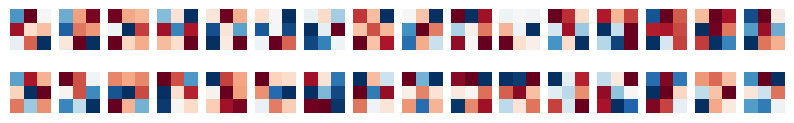

In [9]:
W1 = CNN[0].weight.detach().cpu().numpy()[:, 0]
fig, axes = plt.subplots(2, 16, figsize=(10, 1.5))
for i, a in enumerate(axes.flat):
    a.imshow(W1[i], cmap='RdBu_r'); a.axis('off')
plt.show()

## §4 Conexiunile reziduale (o rulare scurtă pe CIFAR-10)

Un bloc rezidual calculează $\mathbf y = \mathrm{ReLU}(\mathbf x + F(\mathbf x))$. Pe slide-uri, rețelele de 32 de straturi sînt antrenate 15 epoci; aici, 2 epoci pe 10.000 de imagini arată începutul diferenței.

In [10]:
cf = torchvision.datasets.CIFAR10(VISION, train=True, download=True)
Xc = torch.tensor(cf.data[:10000]).permute(0, 3, 1, 2).float() / 255
Xc = (Xc - Xc.mean((0, 2, 3), keepdim=True)) / Xc.std((0, 2, 3), keepdim=True); yc = torch.tensor(cf.targets[:10000])
class Block(nn.Module):
    def __init__(s, c, res):
        super().__init__(); s.res = res
        s.f = nn.Sequential(nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(), nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c))
    def forward(s, x):
        return F.relu(s.f(x) + (x if s.res else 0))
def net(res, n=15):
    return nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), *[Block(16, res) for _ in range(n)],
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 10))
for res in (False, True):
    torch.manual_seed(SEED); m = net(res).to(DEVICE); opt = torch.optim.SGD(m.parameters(), 0.05, momentum=0.9)
    for ep in range(2):
        idx = torch.randperm(10000); tot = 0
        for j in range(0, 10000, 128):
            b = idx[j:j + 128]; loss = F.cross_entropy(m(Xc[b].to(DEVICE)), yc[b].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(b)
    print('residual' if res else 'plain', '32-layer network, training loss after 2 epochs:', round(tot / 10000, 3))

plain 32-layer network, training loss after 2 epochs: 1.924


residual 32-layer network, training loss after 2 epochs: 1.716


## §5 Transferul învățării pe EuroSAT

In [11]:
from PIL import Image
es = torchvision.datasets.EuroSAT(VISION, download=True)            # 27,000 Sentinel-2 tiles, 64 x 64 RGB
root = os.path.join(VISION, 'eurosat', '2750')
DIRS = sorted(os.listdir(root)); DIRS = [d for d in DIRS if os.path.isdir(os.path.join(root, d))]
XE, YE = [], []
for c, d in enumerate(DIRS):
    for f in sorted(os.listdir(os.path.join(root, d))):
        if f.endswith('.jpg'):
            XE.append(np.asarray(Image.open(os.path.join(root, d, f)).convert('RGB'))); YE.append(c)
XE, YE = np.stack(XE), np.array(YE)
rs = np.random.RandomState(SEED); etr, eva, ete = [], [], []
for c in range(10):
    ids = rs.permutation(np.where(YE == c)[0]); n = len(ids)
    etr += list(ids[:int(.6 * n)]); eva += list(ids[int(.6 * n):int(.8 * n)]); ete += list(ids[int(.8 * n):])
etr, eva, ete = map(np.array, (etr, eva, ete))
MUI = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); SDI = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def es_t(ids, size=112):
    x = (torch.tensor(XE[ids]).permute(0, 3, 1, 2).float() / 255 - MUI) / SDI
    return F.interpolate(x, size=(size, size), mode='bilinear', align_corners=False)
print(DIRS, len(etr), len(eva), len(ete))

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake'] 16200 5400 5400


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
body = torchvision.models.resnet18(weights='IMAGENET1K_V1'); body.fc = nn.Identity(); body = body.to(DEVICE).eval()
with torch.no_grad():
    FE = np.concatenate([body(es_t(np.arange(j, min(j + 500, len(XE)))).to(DEVICE)).cpu().numpy() for j in range(0, len(XE), 500)])
sc = StandardScaler().fit(FE[etr])
for n in [10, 100, None]:
    ids = etr if n is None else np.concatenate([np.random.RandomState(SEED).choice(etr[YE[etr] == c], n, replace=False) for c in range(10)])
    lr = LogisticRegression(C=0.1, max_iter=2000).fit(sc.transform(FE[ids]), YE[ids])
    print('frozen ResNet-18 + logistic,', 'all' if n is None else n, 'tiles/class: test accuracy', round(100 * lr.score(sc.transform(FE[ete]), YE[ete]), 2))

frozen ResNet-18 + logistic, 10 tiles/class: test accuracy 79.54


frozen ResNet-18 + logistic, 100 tiles/class: test accuracy 88.65


frozen ResNet-18 + logistic, all tiles/class: test accuracy 93.07


In [13]:
torch.manual_seed(SEED)
ft = torchvision.models.resnet18(weights='IMAGENET1K_V1'); ft.fc = nn.Linear(512, 10); ft = ft.to(DEVICE)
opt = torch.optim.AdamW([{'params': [p for n, p in ft.named_parameters() if not n.startswith('fc')], 'lr': 3e-4},
                         {'params': ft.fc.parameters(), 'lr': 3e-3}], weight_decay=1e-4)
yt = torch.tensor(YE)
for ep in range(2):
    ft.train(); idx = np.random.permutation(etr)
    for j in range(0, len(idx), 64):
        b = idx[j:j + 64]; xb = es_t(b).to(DEVICE)
        if np.random.rand() < .5: xb = xb.flip(3)
        loss = F.cross_entropy(ft(torch.rot90(xb, np.random.randint(4), (2, 3))), yt[b].to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
ft.eval()
with torch.no_grad():
    pe = np.concatenate([ft(es_t(ete[j:j + 500]).to(DEVICE)).argmax(1).cpu().numpy() for j in range(0, len(ete), 500)])
print('fine-tuned ResNet-18 (2 epochs): test accuracy', round(100 * float((pe == YE[ete]).mean()), 2))

fine-tuned ResNet-18 (2 epochs): test accuracy 96.04


## §6 Grad-CAM

$M^c = \mathrm{ReLU}(\sum_o \alpha_o^c A_o)$, unde $\alpha_o^c$ este gradientul mediu al scorului clasei pe harta $o$.

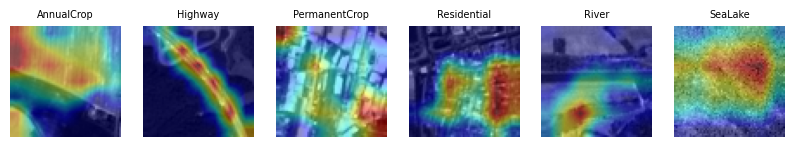

In [14]:
acts = {}
h = ft.layer3.register_forward_hook(lambda m, i, o: acts.__setitem__('a', o))
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for a, c in zip(axes, [0, 3, 4, 7, 8, 9]):
    i = ete[YE[ete] == c][3]; out = ft(es_t(np.array([i])).to(DEVICE)); k = int(out.argmax())
    g = torch.autograd.grad(out[0, k], acts['a'])[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts['a']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(64, 64), mode='bilinear')[0, 0].detach().cpu().numpy()
    a.imshow(XE[i].mean(2), cmap='gray'); a.imshow(cam, cmap='jet', alpha=.45); a.set_title(DIRS[k], fontsize=7); a.axis('off')
h.remove(); plt.show()